In [1]:
!nvidia-smi || echo 'No GPU attached: only the smoke test will work; the real run needs a GPU.'

Sat Oct 24 07:54:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, shutil, zipfile
from google.colab import drive
drive.mount('/content/drive')

ZIP = '/content/claim_study.zip'
DRIVE_ZIP = '/content/drive/MyDrive/claim_study.zip'
if not os.path.exists(ZIP):
    if os.path.exists(DRIVE_ZIP):
        shutil.copy(DRIVE_ZIP, ZIP)
    else:
        print('Zip not found in Drive. Choose claim_study.zip from your computer:')
        from google.colab import files
        up = files.upload()
        name = list(up.keys())[0]
        if name != 'claim_study.zip':
            os.rename('/content/' + name, ZIP)
zipfile.ZipFile(ZIP).extractall('/content')
%cd /content/claim_study

# data/ (your annotations) and results/ (finished folds) live in Google Drive, so a disconnect loses nothing
for local, remote in [('data', 'claim_data'), ('results', 'claim_results')]:
    target = f'/content/drive/MyDrive/{remote}'
    os.makedirs(target, exist_ok=True)
    if os.path.lexists(local):
        os.remove(local) if os.path.islink(local) else shutil.rmtree(local)
    os.symlink(target, local)
!ls -la

Mounted at /content/drive
/content/claim_study
total 56
drwxr-xr-x 5 root root 4096 Oct 24 07:55 .
drwxr-xr-x 1 root root 4096 Oct 24 07:55 ..
drwxr-xr-x 2 root root 4096 Oct 24 07:55 claim
-rw-r--r-- 1 root root 4602 Oct 24 07:55 cli.py
-rw-r--r-- 1 root root 7446 Oct 24 07:55 colab_runner.ipynb
lrwxrwxrwx 1 root root   33 Oct 24 07:55 data -> /content/drive/MyDrive/claim_data
drwxr-xr-x 2 root root 4096 Oct 24 07:55 docs
-rw-r--r-- 1 root root 7029 Oct 24 07:55 README.md
-rw-r--r-- 1 root root   83 Oct 24 07:55 requirements.txt
lrwxrwxrwx 1 root root   36 Oct 24 07:55 results -> /content/drive/MyDrive/claim_results
-rw-r--r-- 1 root root 3859 Oct 24 07:55 run_experiments.py
-rw-r--r-- 1 root root 1610 Oct 24 07:55 smoke_test.py
drwxr-xr-x 2 root root 4096 Oct 24 07:55 tests


In [3]:
!pip install -q -r requirements.txt

In [4]:
# optional: faster, rate-limit-free model downloads (Colab > key icon > add secret HF_TOKEN)
try:
    from google.colab import userdata
    os.environ['HF_TOKEN'] = userdata.get('HF_TOKEN')
    print('HF_TOKEN set')
except Exception:
    print('No HF_TOKEN secret (fine: downloads still work, just unauthenticated)')

No HF_TOKEN secret (fine: downloads still work, just unauthenticated)


In [5]:
!python smoke_test.py

dataset OK: 12 synthetic docs, 24 records
parsers OK
metrics OK (perfect predictions give F1 = 1.0, kappa = 1.0)
run zero_shot_text fold 1/3 on 4 docs
run zero_shot_json fold 1/3 on 4 docs
run few_shot_json fold 1/3 on 4 docs
run rag_json fold 1/3 on 4 docs
run zero_shot_text fold 2/3 on 4 docs
run zero_shot_json fold 2/3 on 4 docs
run few_shot_json fold 2/3 on 4 docs
run rag_json fold 2/3 on 4 docs
run zero_shot_text fold 3/3 on 4 docs
run zero_shot_json fold 3/3 on 4 docs
run few_shot_json fold 3/3 on 4 docs
run rag_json fold 3/3 on 4 docs
done -> /tmp/tmpv9zux9s2/preds
# Results summary

Docs: 12. Best method (relaxed F1, no verification): **zero_shot_text**.

## Main results

| method | n_pred | parse_ok | halluc_rate | P_strict | R_strict | F1_strict [95% CI] | P_relaxed | R_relaxed | F1_relaxed [95% CI] | P_value_unit | R_value_unit | F1_value_unit [95% CI] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| zero_shot_text | 27 | 1.00 | 0.000 | 0.000 | 0.000 | 0.000 [0.000,

In [6]:
!python run_experiments.py --stages fetch sheet --n 150


===== STAGE: fetch =====
arXiv request failed (HTTP Error 500: Internal Server Error); using the 121 abstracts collected so far
saved 121 abstracts -> data/snippets.jsonl

===== STAGE: sheet =====
config.json: 100% 661/661 [00:00<00:00, 2.58MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 18.5MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 63.8MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 113MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 112MB/s]
model.safetensors.index.json: 100% 35.6k/35.6k [00:00<00:00, 72.8MB/s]
Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0% 0/2 [00:00<?, ?it/s]
Reconstructing (incomplete total...):   0% 0.00/6.17G [00:00<?, ?B/s]         
Reconstructing (incomplete total...):   0% 0.00/6.17G [00:00<?, ?B/s]
Reconstructing (incomplete total...):  26% 1.62G/6.17G [00:17<00:49, 92.8MB/s, 81.0MB/s  ]

Reconstructing (incomplete total...):  93% 5.73G/6.17G [00:50<00:03, 140MB/s,  123MB/s  ]
R

In [7]:
from google.colab import files
files.download('data/annotation_sheet_A.csv'); files.download('data/annotation_sheet_B.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# only if you edited the CSVs on your computer: upload them here (names must stay annotation_sheet_A.csv / _B.csv)
from google.colab import files
up = files.upload()
for n in up: os.replace(n, f'data/{n}')

Saving annotation_sheet_A.csv to annotation_sheet_A.csv
Saving annotation_sheet_B.csv to annotation_sheet_B.csv


OSError: [Errno 18] Invalid cross-device link: 'annotation_sheet_A.csv' -> 'data/annotation_sheet_A.csv'

In [9]:
import shutil
for n in ['annotation_sheet_A.csv', 'annotation_sheet_B.csv']:
    shutil.move(n, f'data/{n}')
!ls -la data

lrwxrwxrwx 1 root root 33 Oct 24 07:55 data -> /content/drive/MyDrive/claim_data


In [10]:
!python run_experiments.py --stages gold


===== STAGE: gold =====
121 docs, 194 records -> data/gold_A.jsonl; 118 validation issues
  - 2512.00731v1 [ErOCl | optical gain coefficient | 1500 dB/cm]: value not found in text
  - 2512.00731v1 [ErOCl | lasing threshold power | 7 μW]: value not found in text
  - 2605.12854v1 [2D materials | kinetic energy loss | around 400 eV]: value not found in text
  - 2605.12854v1 [2D materials | backscattered electron yields | significant differences]: value not found in text
  - 2606.18090v1 [rubrene | reorganization energy | 29 meV]: value not found in text
  - 2606.18090v1 [rubrene | reorganization energy | 39 meV]: value not found in text
  - 2606.29813v1 [EuAuAs | magnetoresistance | butterfly-shaped hysteresis]: value not found in text
  - 2602.04280v1 [zinc-based electrochromic device | lifespan | 15,000 cycles]: value not found in text
  - 2605.13458v1 [monolayer 1T-VSe2 | symmetry-lowering distortions | into larger superstructures]: value not found in text
  - 2512.01743v1 [1T$'$-MoTe

In [11]:
!python run_experiments.py --stages run --folds 5 --run-name run1


===== STAGE: run =====
Loading weights: 100% 434/434 [00:13<00:00, 33.18it/s]
modules.json: 100% 349/349 [00:00<00:00, 1.75MB/s]
config_sentence_transformers.json: 100% 116/116 [00:00<00:00, 572kB/s]
README.md: 100% 10.5k/10.5k [00:00<00:00, 27.4MB/s]
sentence_bert_config.json: 100% 53.0/53.0 [00:00<00:00, 300kB/s]
config.json: 100% 612/612 [00:00<00:00, 2.82MB/s]

model.safetensors: downloading bytes:  79% 71.9M/90.9M [00:01<00:00, 87.4MB/s, 6.00MB/s  ]
model.safetensors: downloading bytes: 100% 85.0M/85.0M [00:01<00:00, 63.5MB/s, 8.02MB/s  ]
model.safetensors: reconstructing file: 100% 90.9M/90.9M [00:01<00:00, 67.8MB/s, 8.80MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 4382.81it/s]
tokenizer_config.json: 100% 350/350 [00:00<00:00, 1.94MB/s]
vocab.txt: 100% 232k/232k [00:00<00:00, 22.4MB/s]
tokenizer.json: 100% 466k/466k [00:00<00:00, 55.1MB/s]
special_tokens_map.json: 100% 112/112 [00:00<00:00, 676kB/s]
config.json: 100% 190/190 [00:00<00:00, 837kB/s]
run zero_shot_text fold 

In [12]:
!python run_experiments.py --stages analyze --run-name run1
print(open('results/run1/summary.md').read()[:6000])


===== STAGE: analyze =====
# Results summary

Docs: 121. Best method (relaxed F1, no verification): **zero_shot_json**.

## Main results

| method | n_pred | parse_ok | halluc_rate | P_strict | R_strict | F1_strict [95% CI] | P_relaxed | R_relaxed | F1_relaxed [95% CI] | P_value_unit | R_value_unit | F1_value_unit [95% CI] |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| zero_shot_text | 214 | 1.00 | 0.514 | 0.037 | 0.041 | 0.039 [0.010,0.074] | 0.079 | 0.088 | 0.083 [0.034,0.143] | 0.126 | 0.139 | 0.132 [0.074,0.202] |
| zero_shot_json | 194 | 0.96 | 0.613 | 0.964 | 0.964 | 0.964 [0.933,0.988] | 0.969 | 0.969 | 0.969 [0.939,0.992] | 0.974 | 0.974 | 0.974 [0.946,0.995] |
| few_shot_json | 162 | 0.94 | 0.722 | 0.148 | 0.124 | 0.135 [0.084,0.190] | 0.228 | 0.191 | 0.208 [0.142,0.272] | 0.259 | 0.216 | 0.236 [0.162,0.314] |
| rag_json | 149 | 0.96 | 0.698 | 0.134 | 0.103 | 0.117 [0.065,0.174] | 0.248 | 0.191 | 0.216 [0.143,0.296] | 0.302 | 0.232 | 0.262 [0.187,0.343] |
| lora_js

fig1_f1_by_method


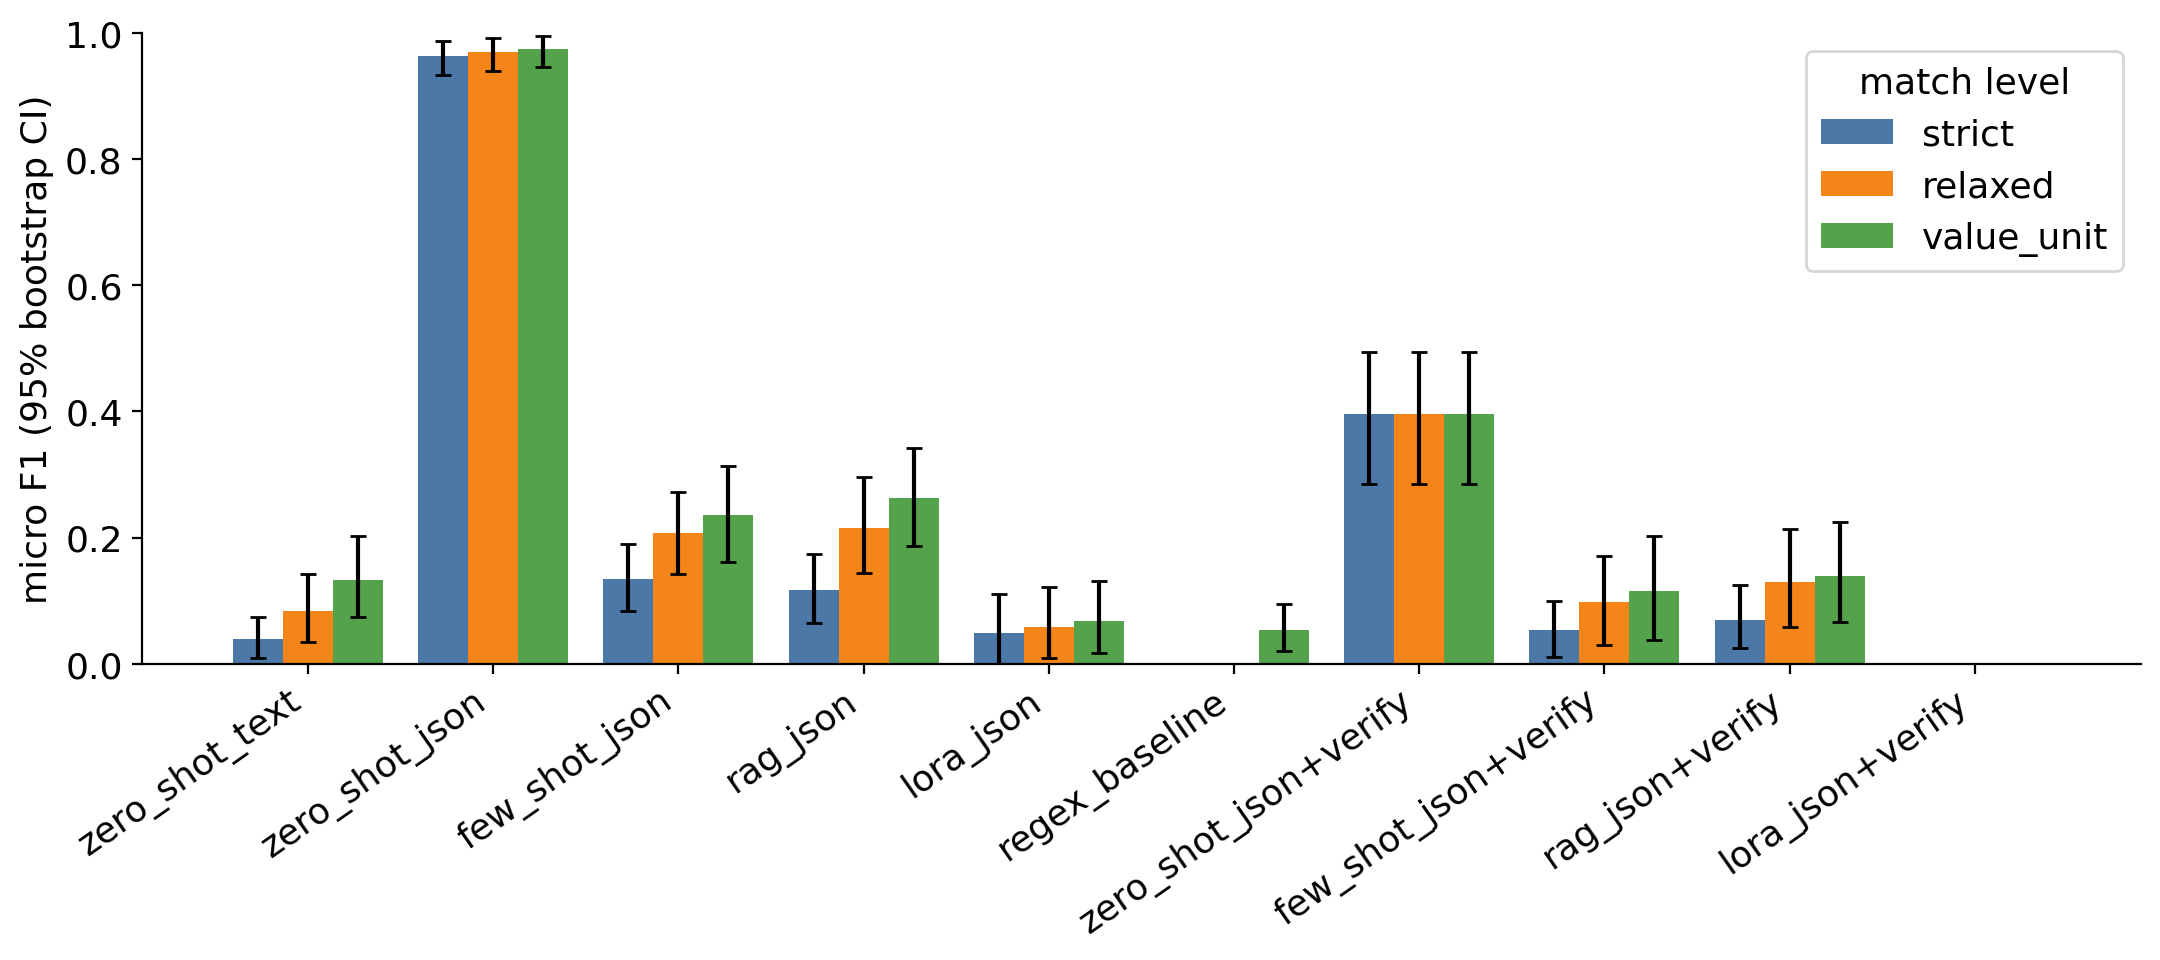

fig2_hallucination_verification


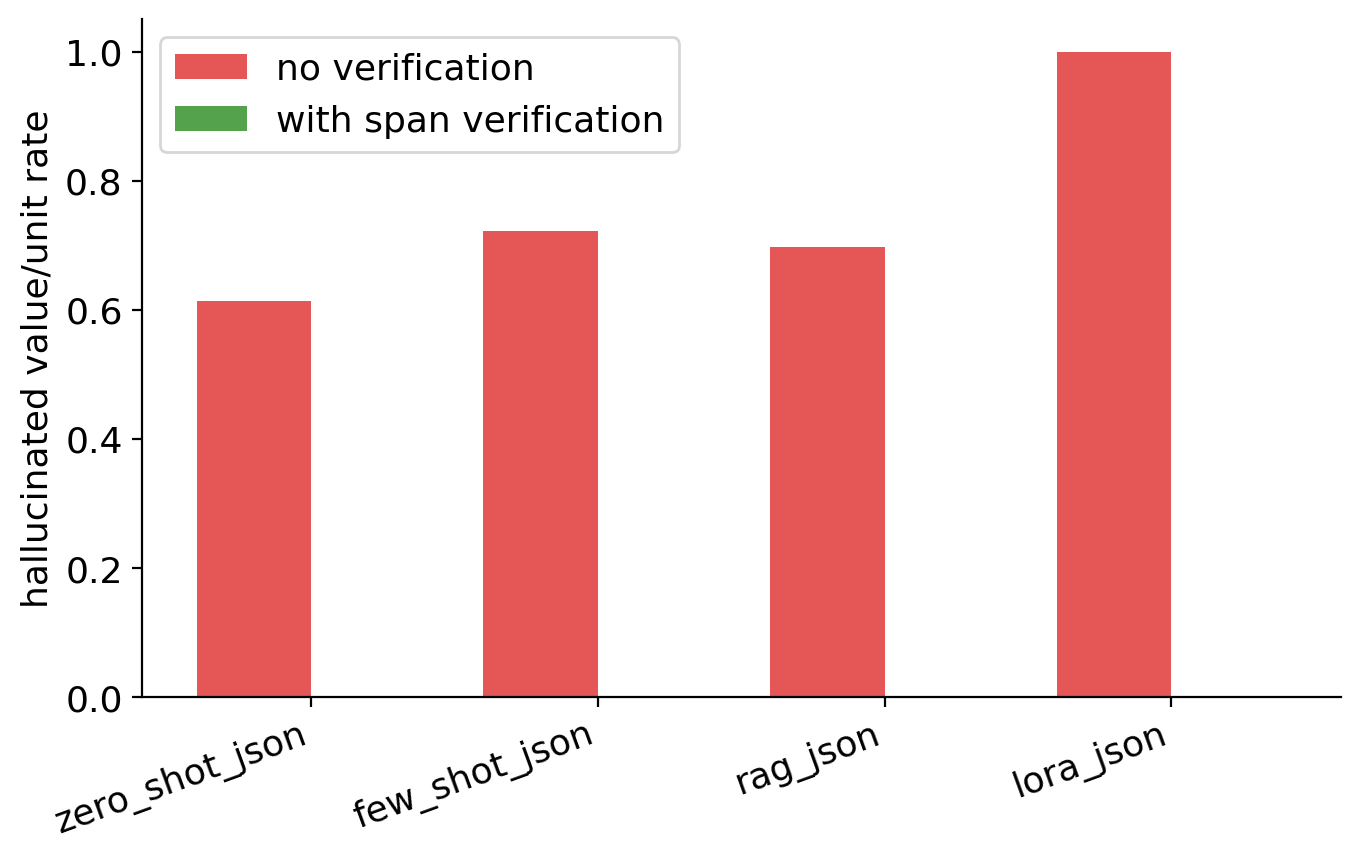

fig3_precision_recall_verification


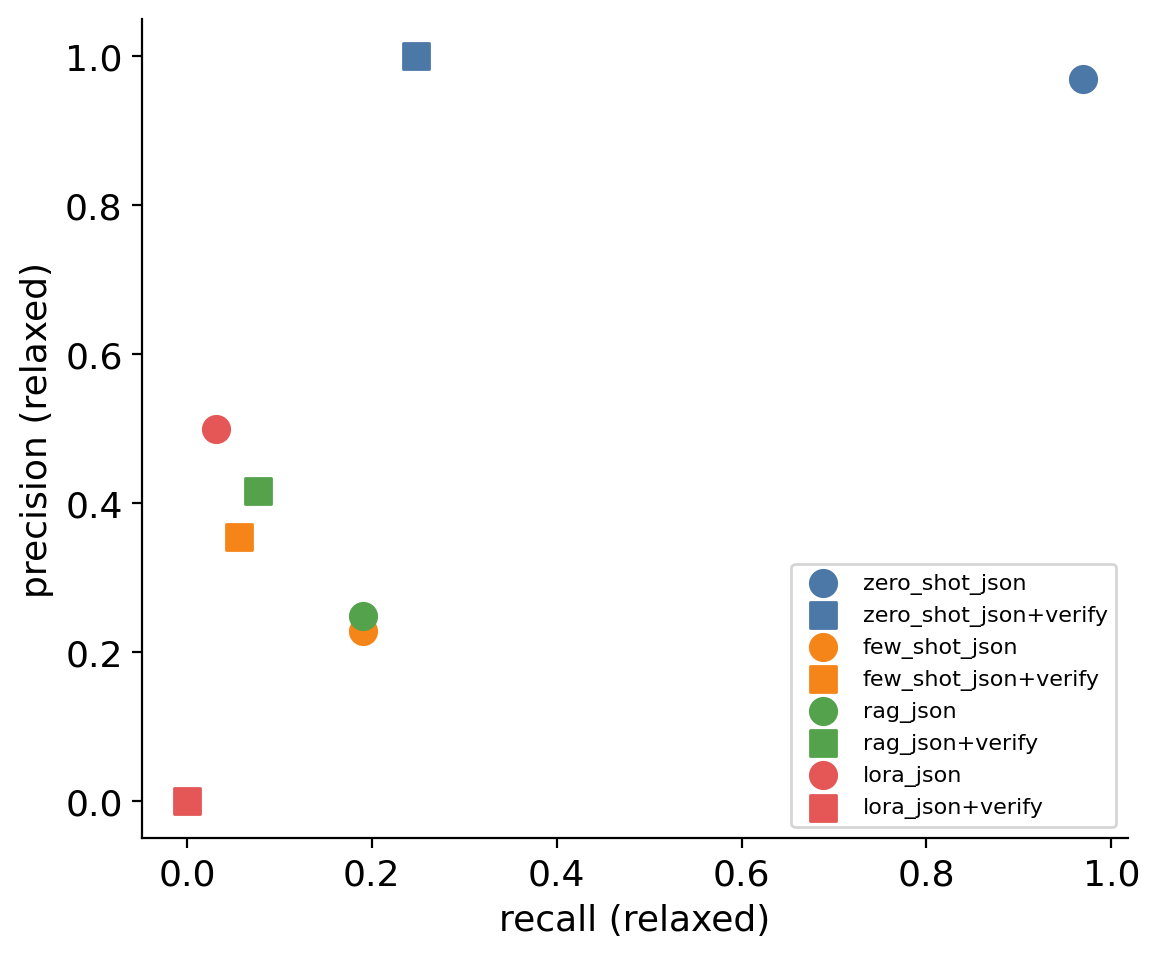

fig4_reliability


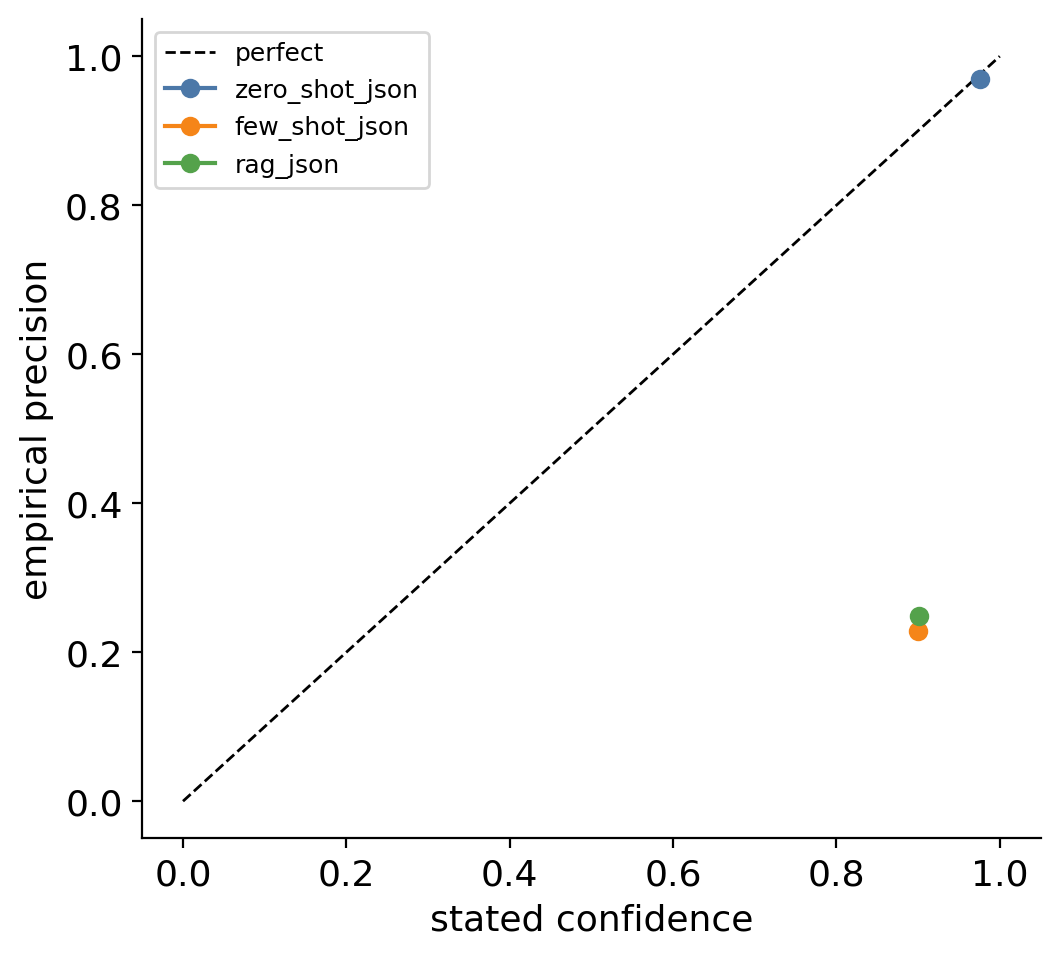

fig5_error_taxonomy


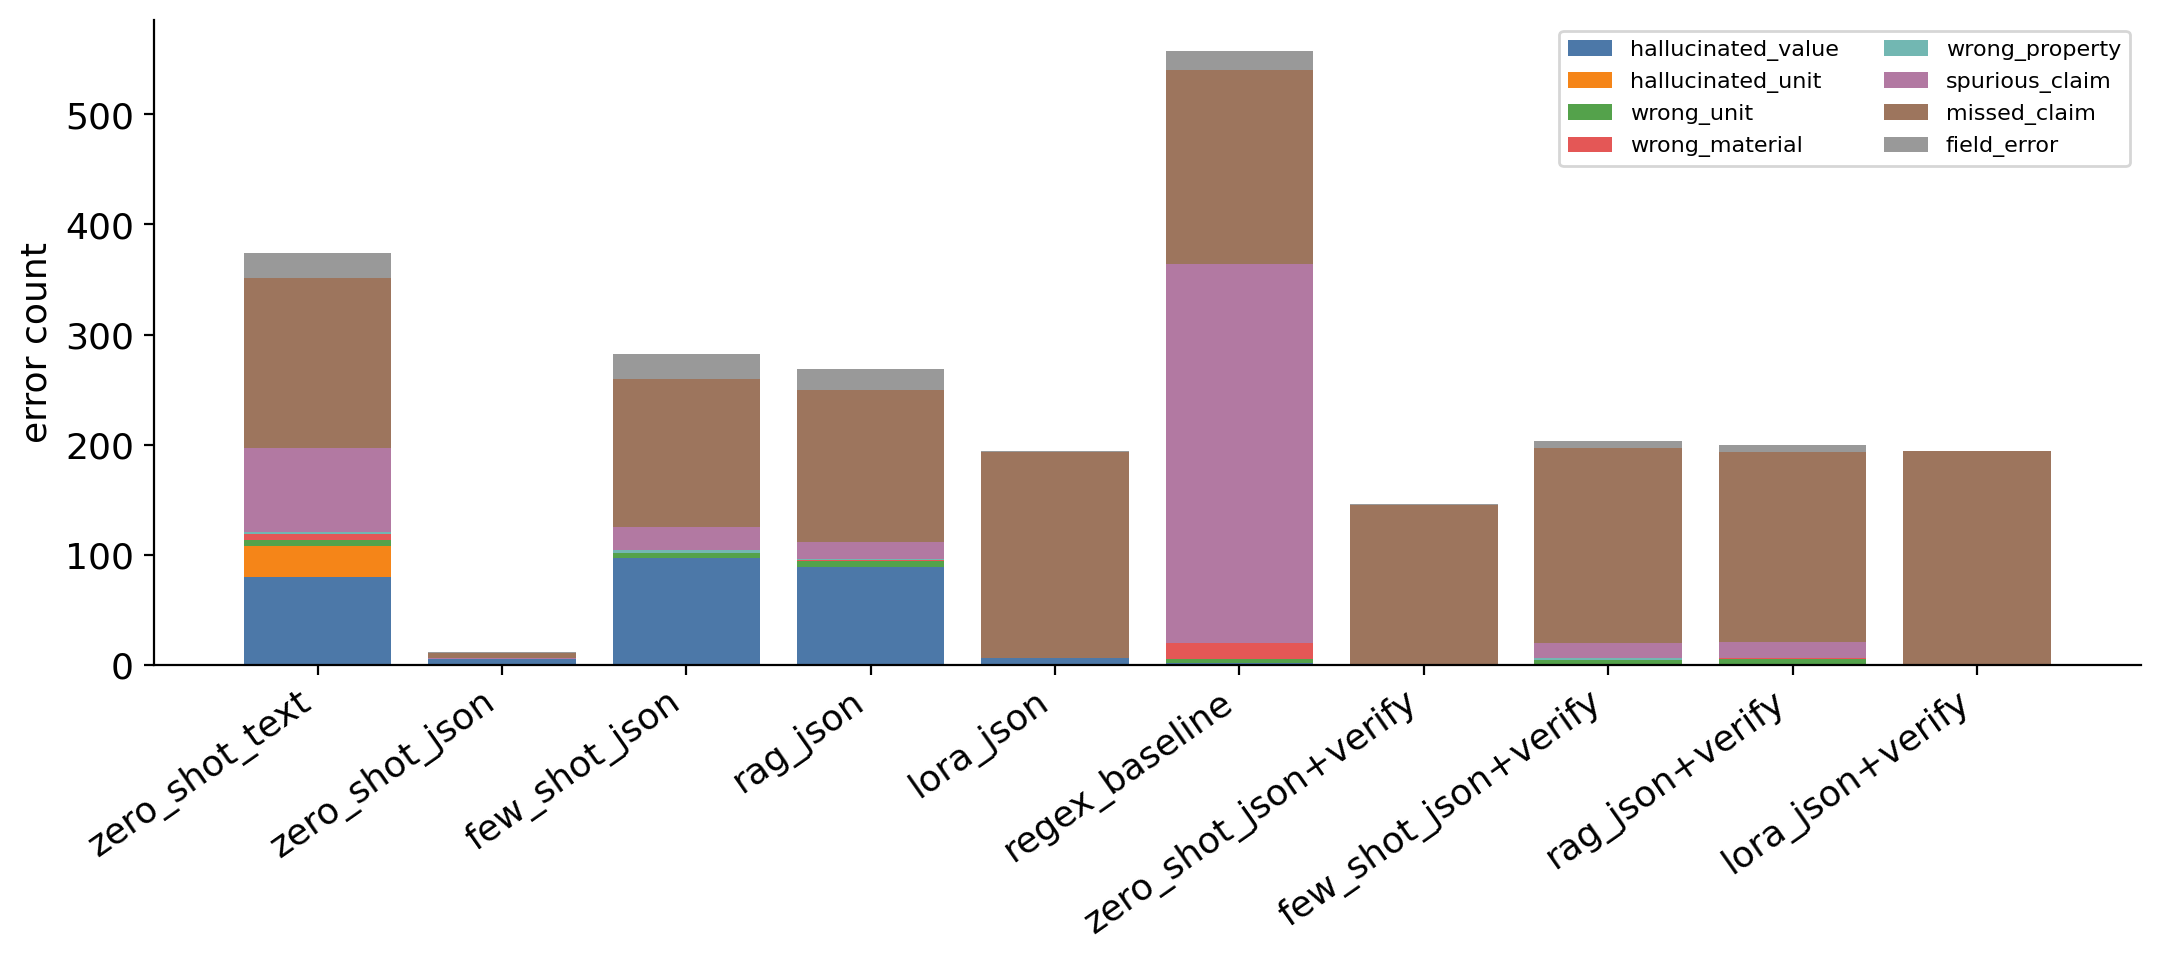

In [13]:
import glob
from IPython.display import Image, display
run = 'results/run1'
for f in ['fig1_f1_by_method','fig2_hallucination_verification','fig3_precision_recall_verification','fig4_reliability','fig5_error_taxonomy']:
    p = f'{run}/figures/{f}.png'
    if glob.glob(p):
        print(f); display(Image(p, width=700))

In [14]:
import pandas as pd
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 80)
pd.read_csv('results/run1/tables/failures_to_review.csv').drop(columns=['text']).head(20)

,method,doc_id,type,auto_category,material,property,value,unit,human_category
0,zero_shot_json,2512.01459v1,FN,missed_claim,"Ag(Cu,In,Ga)S2",open-circuit voltage,948,mV,NaN
1,zero_shot_json,2512.01253v2,FP,hallucinated_value,SrTiO$_3$,second harmonic generation,spatially inhomogeneous,NaN,NaN
2,zero_shot_json,2605.12854v1,FN,missed_claim,2D materials,backscattered electron yields,significant differences,NaN,NaN
3,zero_shot_json,2606.27887v1,FP,spurious_claim,Pb0.6Sr0.4ZrO3 thin films,charge/discharge capability,microsecond-scale,NaN,NaN
4,zero_shot_json,2606.17012v1,FP,hallucinated_value,sub-3 nm and sub-20 nm diameter nanopore arrays,ionic conductance,stronger deviations from linearity at lower salt concentrations,NaN,NaN
5,zero_shot_json,2512.01253v2,FN,missed_claim,SrTiO$_3$,second harmonic generation,short-lived,NaN,NaN
6,zero_shot_json,2606.17012v1,FN,missed_claim,sub-3 nm and sub-20 nm diameter nanopore arrays,ionic conductance,scaling laws,NaN,NaN
7,zero_shot_json,2606.17336v1,FP,hallucinated_value,Ni film,vapor production temperature,1725 K,NaN,NaN
8,zero_shot_json,2606.17336v1,FN,field_error,Ni film,melting point,1725 K,NaN,NaN
9,zero_shot_json,2605.12854v1,FP,hallucinated_value,2D materials,kinetic energy loss,400 eV,NaN,NaN


In [15]:
!zip -q -r /content/my_claim_results.zip results/
from google.colab import files
files.download('/content/my_claim_results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>